In [1]:
# import
import os, sys, pickle
import numpy as np
import pandas as pd
import scipy as sp
from tqdm import tqdm
from scipy import signal
from scipy.stats import gamma
from nilearn.glm.first_level import make_first_level_design_matrix, compute_regressor
from nilearn.glm.first_level import FirstLevelModel

# import plotting libraries
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 8})
plt.rcParams["svg.fonttype"] = "none"
import seaborn as sns
from nilearn import datasets
from nilearn import plotting

sys.path.extend([r'/home/lindenmp/research_projects/snaplab_tools'])
sys.path.extend([r'/home/lindenmp/research_projects/nctpy/src'])

from nilearn.glm import first_level
from sklearn.linear_model import LinearRegression
from snaplab_tools.plotting.plotting import categorical_kde_plot, reg_plot, brain_scatter_plot, null_plot, surface_plot
from src.ints import compute_timescales, compute_autocorrelation_with_hrf
from src.plotting import plot_autocorrelation_analysis

In [2]:
from nilearn.plotting import plot_design_matrix

import warnings
warnings.simplefilter('ignore', UserWarning)

## Setup

In [ ]:
# directory where data is stored
indir = '/home/lindenmp/research_projects/intrinsic_neural_timescales/data'
which_data = 'HCP-YA'
outdir = '/home/lindenmp/research_projects/intrinsic_neural_timescales/results/{0}'.format(which_data)

if not os.path.exists(outdir):
    os.makedirs(outdir)

atlas = 'Schaefer4007'
if atlas == 'Schaefer4007':
    n_parcels = 400
    n_nodes = 400
elif atlas == 'Schaefer2007':
    n_parcels = 200
    n_nodes = 200
elif atlas == 'Schaefer1007':
    n_parcels = 100
    n_nodes = 100
    
if which_data == 'HCP-YA':
    tr = 1.0
    rest_scans = ['rfMRIREST17TPA', 'rfMRIREST27TAP', 'rfMRIREST37TPA', 'rfMRIREST47TAP']
    tasks = ['tfMRIMOVIE17TAP', 'tfMRIMOVIE27TPA', 'tfMRIMOVIE37TPA', 'tfMRIMOVIE47TAP']
    timing_files = ['7T_MOVIE1_CC1_v2_Video_Timing.csv', '7T_MOVIE2_HO1_v2_Video_Timing.csv', '7T_MOVIE3_CC2_v2_Video_Timing.csv', '7T_MOVIE4_HO2_v2_Video_Timing.csv']

In [4]:
# plot states on brain surface
annot_dir = '/home/lindenmp/research_projects/nctpy/data'
lh_annot_file = os.path.join(annot_dir, 'schaefer_parc', 'fsaverage5', 'lh.Schaefer2018_{0}Parcels_7Networks_order.annot'.format(n_parcels))
rh_annot_file = os.path.join(annot_dir, 'schaefer_parc', 'fsaverage5', 'rh.Schaefer2018_{0}Parcels_7Networks_order.annot'.format(n_parcels))
fsaverage = datasets.fetch_surf_fsaverage(mesh="fsaverage5")
cmap = "viridis"

## 7T data

In [5]:
subject_ids = np.loadtxt(os.path.join(indir, '{0}-7T_{1}_subjids.txt'.format(which_data, atlas)), dtype=str)
n_subs = len(subject_ids)
print(n_subs)

173


In [6]:
rest_ts = np.load(os.path.join(indir, '{0}-7T_{1}_rsts.npy'.format(which_data, atlas)))

rest_timescales = dict()
for i, which_scan in enumerate(rest_scans):
    print(which_scan)
    rest_timescales[which_scan] = compute_timescales(rest_ts[:, :, i, :], return_mean=False).T
    print(rest_timescales[which_scan].shape)

rfMRIREST17TPA
173 400


100%|██████████| 173/173 [00:10<00:00, 16.75it/s]


(173, 400)
rfMRIREST27TAP
173 400


100%|██████████| 173/173 [00:10<00:00, 16.80it/s]


(173, 400)
rfMRIREST37TPA
173 400


100%|██████████| 173/173 [00:10<00:00, 17.03it/s]


(173, 400)
rfMRIREST47TAP
173 400


100%|██████████| 173/173 [00:10<00:00, 17.04it/s]

(173, 400)


tfMRIMOVIE17TAP
(921, 400, 173)


  0%|          | 0/173 [00:00<?, ?it/s]

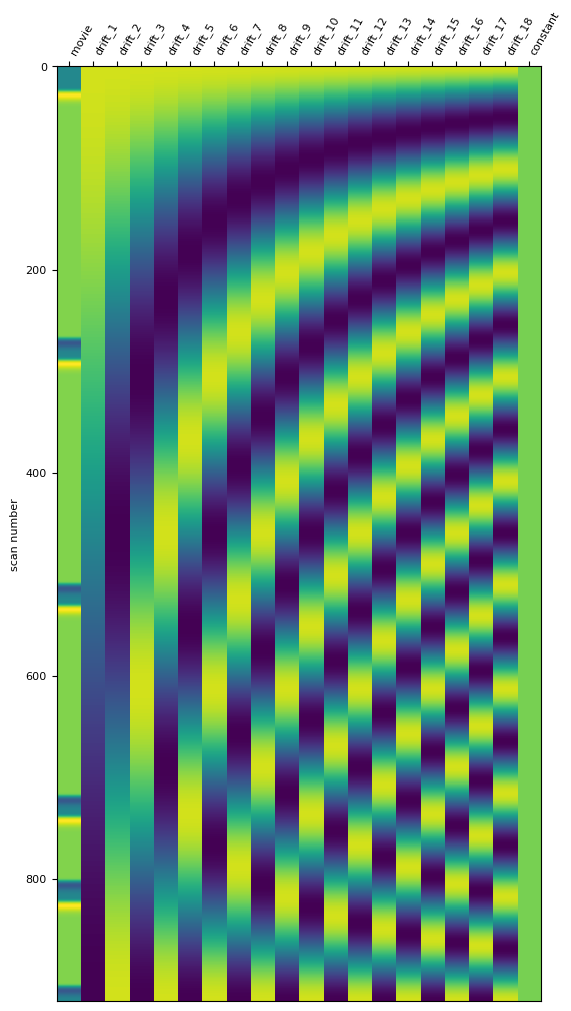

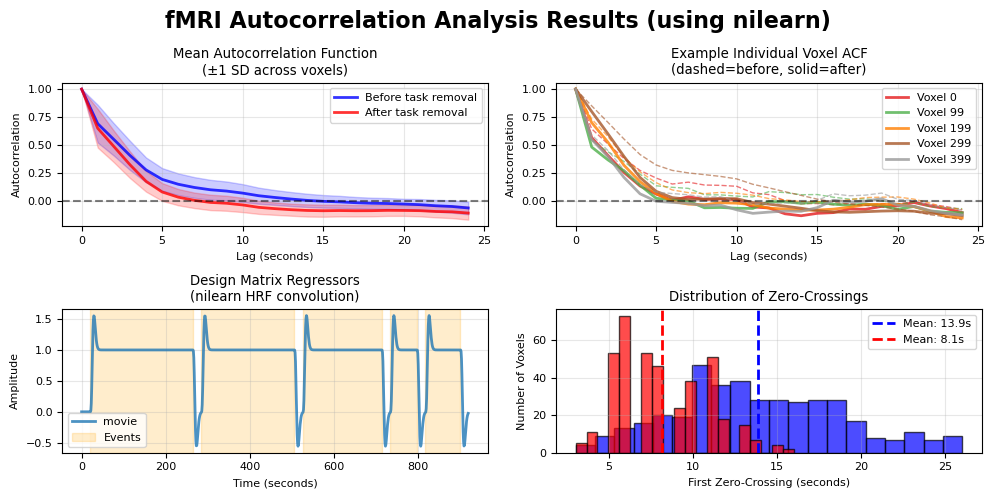

100%|██████████| 173/173 [00:26<00:00,  6.64it/s]


(173, 400)
tfMRIMOVIE27TPA
(918, 400, 173)


  0%|          | 0/173 [00:00<?, ?it/s]

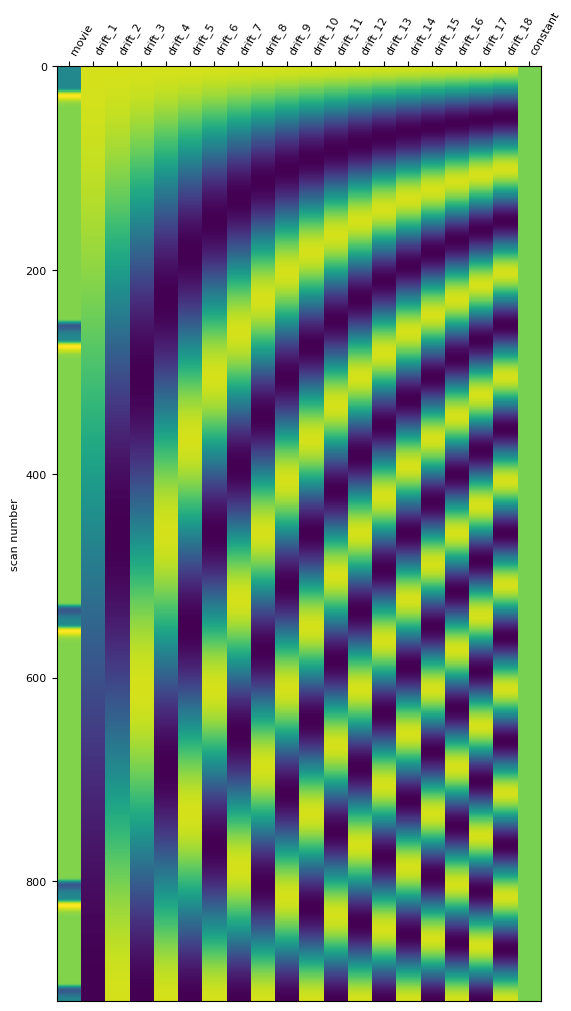

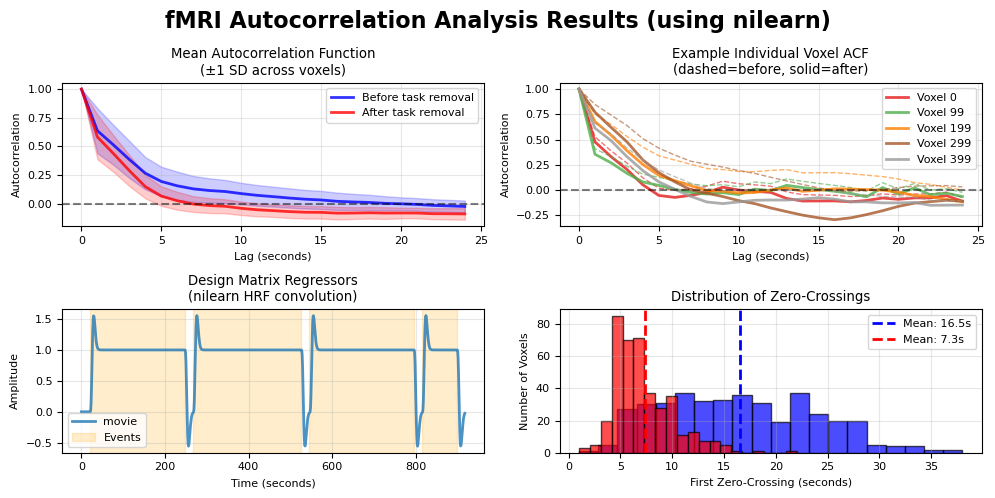

100%|██████████| 173/173 [00:26<00:00,  6.63it/s]


(173, 400)
tfMRIMOVIE37TPA
(915, 400, 173)


  0%|          | 0/173 [00:00<?, ?it/s]

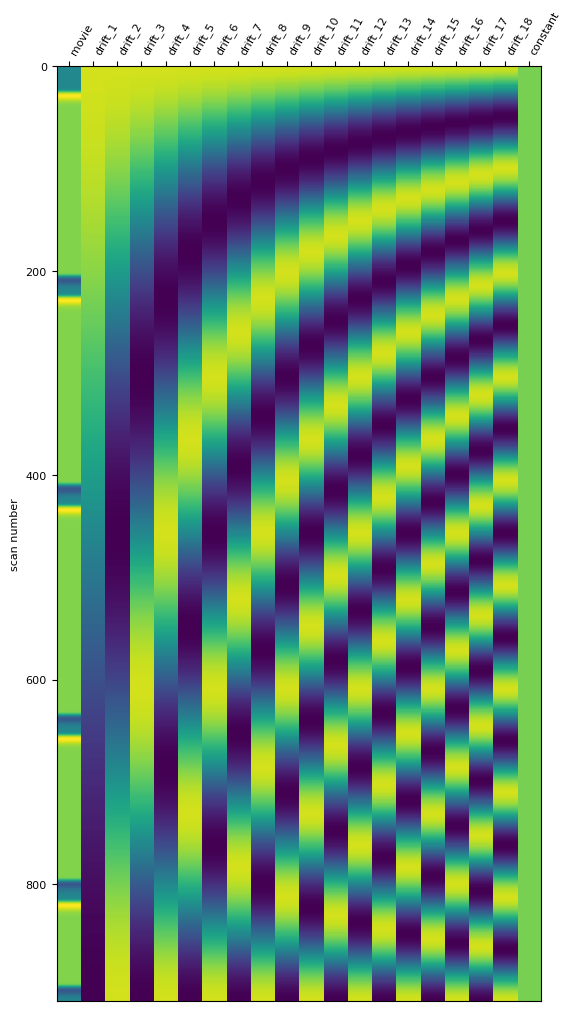

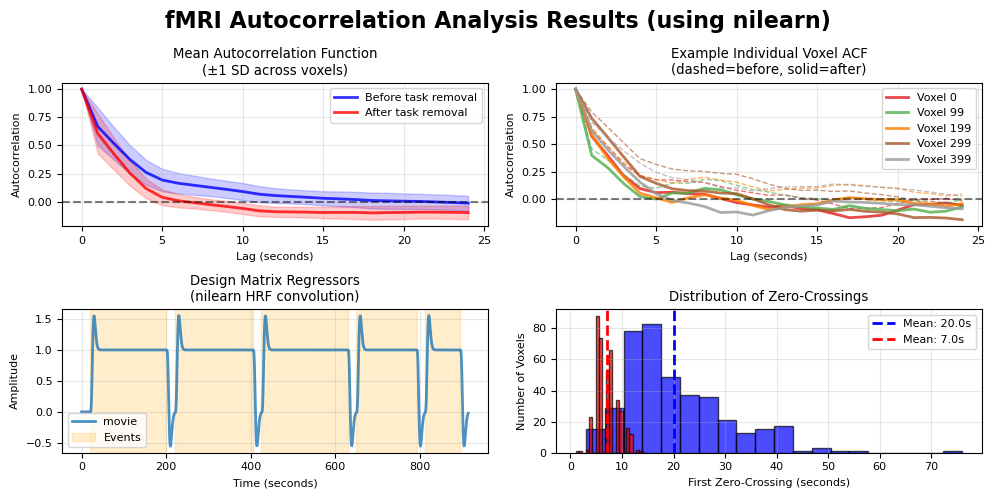

100%|██████████| 173/173 [00:25<00:00,  6.74it/s]


(173, 400)
tfMRIMOVIE47TAP
(901, 400, 173)


  0%|          | 0/173 [00:00<?, ?it/s]

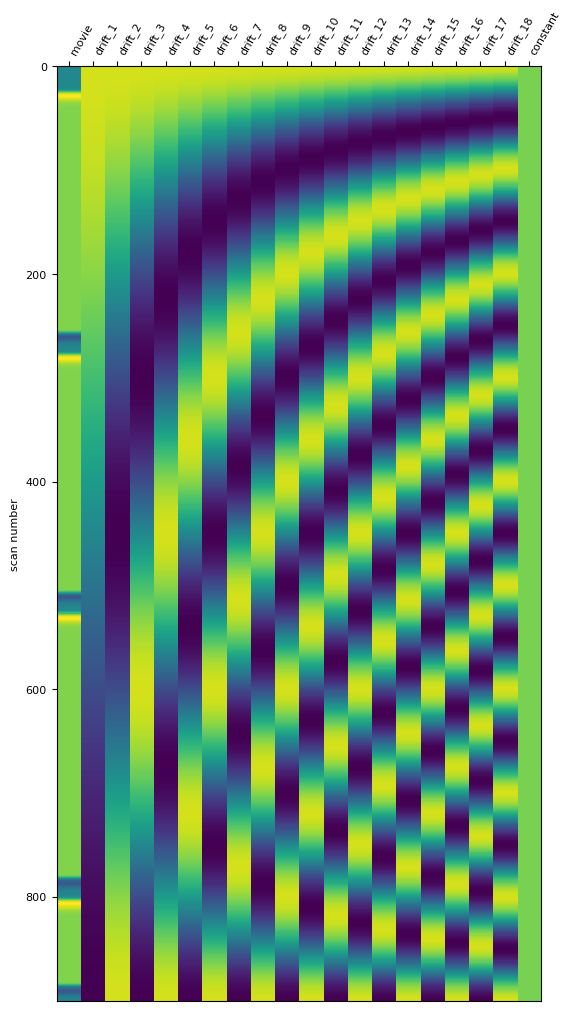

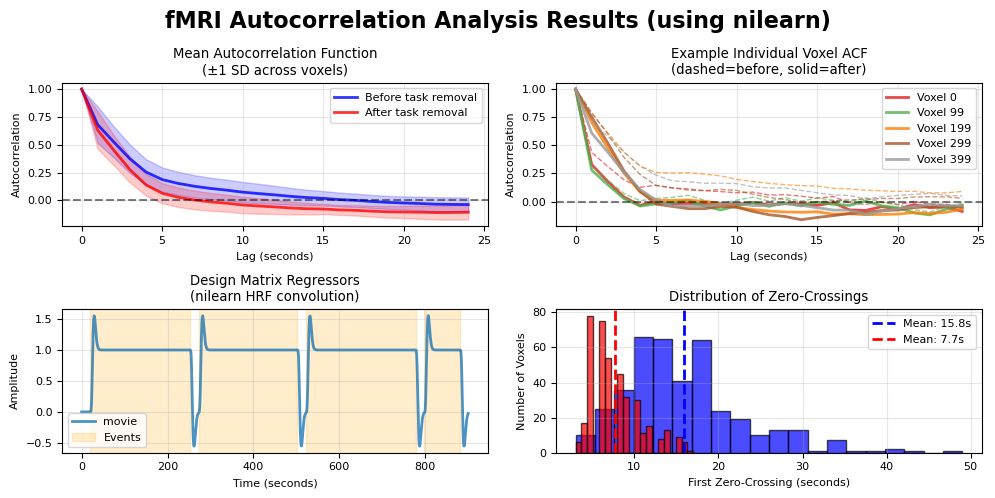

100%|██████████| 173/173 [00:25<00:00,  6.88it/s]

(173, 400)


In [7]:
movie_timescales = dict()
for i, which_scan in enumerate(tasks):
    print(which_scan)
    movie_timescales[which_scan] = np.zeros((n_subs, n_parcels))

    task_ts = np.load(os.path.join(indir, '{0}-7T_{1}_taskts-{2}.npy'.format(which_data, atlas, which_scan)))
    print(task_ts.shape)
    
    block_design_file = os.path.join(indir, 'movie_data', timing_files[i])
    block_design_data = pd.read_csv(block_design_file)
    block_design_data = block_design_data.loc[block_design_data['movie.block'] != 0.0]

    # Create events DataFrame for nilearn (task blocks only by default)
    task_events = pd.DataFrame({
        'onset': block_design_data['block_start_time'],
        'duration': block_design_data['block_duration'], 
        'trial_type': 'movie'
    }).dropna().sort_values('onset').reset_index(drop=True)

    # movie_timescales[which_scan] = compute_timescales(task_ts, return_mean=False).T
    for j in tqdm(np.arange(n_subs)):
        fmri_data = task_ts[:, :, j].T
        autocorr_raw, zero_crossings_raw, autocorr_resid, zero_crossings_resid, residuals, design_matrix = compute_autocorrelation_with_hrf(fmri_data, task_events, tr, 
                                                                                                                                            hrf_model='glover', drift_model='cosine')
        movie_timescales[which_scan][j, :] = zero_crossings_resid
        if j == 0:
            plot_design_matrix(design_matrix)
            plot_autocorrelation_analysis(autocorr_raw, autocorr_resid, zero_crossings_raw, zero_crossings_resid, design_matrix, task_events, tr)
            plt.show()
    print(movie_timescales[which_scan].shape)

In [8]:
for which_scan in rest_timescales.keys():
    np.save(os.path.join(outdir, '{0}-7T_{1}_{2}_timescales_acflag.npy'.format(which_data, atlas, which_scan)), rest_timescales[which_scan])

for which_scan in movie_timescales.keys():
    np.save(os.path.join(outdir, '{0}-7T_{1}_{2}_timescales_acflag.npy'.format(which_data, atlas, which_scan)), movie_timescales[which_scan])